# Дополнительное исследование данных для исключения нечестности полученных метрик и улучшения протокола

### Импорты и загрузка данных

In [ ]:
import sys
sys.path.append('../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

# Загрузка всех взаимодействий целиком (сырые, до сплита)
# Нужны для полной картины
interactions = pd.read_csv('../data/raw/interactions.csv', parse_dates=['last_watch_dt'])
interactions = interactions.dropna(subset=['watched_pct']).reset_index(drop=True)

print(f"Всего взаимодействий: {len(interactions):,}")
print(f"Уникальных юзеров:     {interactions['user_id'].nunique():,}")
print(f"Уникальных айтемов:    {interactions['item_id'].nunique():,}")

Всего взаимодействий: 5,475,423
Уникальных юзеров:     962,151
Уникальных айтемов:    15,605


**Repeat rate**

In [ ]:
# Для каждой пары (user_id, item_id) — сколько раз она встречается
pair_counts = interactions.groupby(['user_id', 'item_id']).size()

total_pairs = len(pair_counts)
repeated_pairs = (pair_counts > 1).sum()
repeat_events = (pair_counts[pair_counts > 1] - 1).sum()

print(f"Уникальных пар (user, item):     {total_pairs:,}")
print(f"Пар, встретившихся >1 раза:      {repeated_pairs:,} ({repeated_pairs/total_pairs*100:.2f}%)")
print(f"Всего повторных взаимодействий:  {repeat_events:,} ({repeat_events/len(interactions)*100:.2f}%)")

Уникальных пар (user, item):     5,475,423
Пар, встретившихся >1 раза:      0 (0.00%)
Всего повторных взаимодействий:  0 (0.00%)


*Открыта удивительная особенность датасета KION: в датасете совсем нет повторных просмотров: каждый юзер смотрит каждый фильм/сериал ровно 1 раз,  а если и есть иные случае, то мы их абсолютное меньшинство и мы их отфильтровали*

### Кол-во активных дней у пользователя

Количество активных дней на юзера:
count    962151.000000
mean          3.655180
std           5.099913
min           1.000000
25%           1.000000
50%           2.000000
75%           4.000000
90%           8.000000
95%          12.000000
99%          25.000000
max         158.000000
Name: last_watch_dt, dtype: float64

Юзеров с 1 активным днём: 420,809 (43.7%)
Юзеров с 2+ активными днями: 541,342 (56.3%)
Юзеров с 5+ активными днями: 217,062 (22.6%)


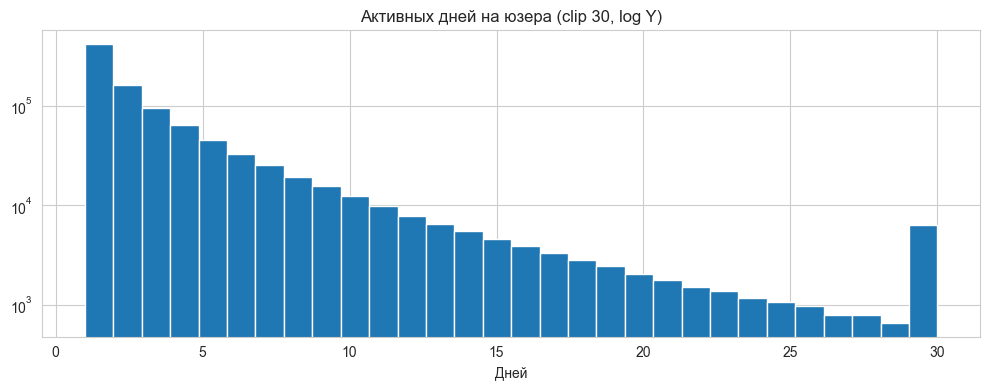

In [ ]:
user_days = interactions.groupby('user_id')['last_watch_dt'].nunique()

print("Количество активных дней на юзера:")
print(user_days.describe(percentiles=[.25, .5, .75, .9, .95, .99]))

print(f"\nЮзеров с 1 активным днём: {(user_days == 1).sum():,} ({(user_days == 1).mean()*100:.1f}%)")
print(f"Юзеров с 2+ активными днями: {(user_days >= 2).sum():,} ({(user_days >= 2).mean()*100:.1f}%)")
print(f"Юзеров с 5+ активными днями: {(user_days >= 5).sum():,} ({(user_days >= 5).mean()*100:.1f}%)")

fig, ax = plt.subplots(figsize=(10, 4))
user_days.clip(upper=30).hist(bins=30, ax=ax, log=True)
ax.set_title('Активных дней на юзера (clip 30, log Y)')
ax.set_xlabel('Дней')
plt.tight_layout()
plt.show()

### Кол-во просмотренных айтемов в паре (usrt_id, day)

Айтемов на активный день:
count    3.516835e+06
mean     1.556918e+00
std      1.267807e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      2.000000e+00
90%      3.000000e+00
99%      6.000000e+00
max      2.500000e+02
dtype: float64


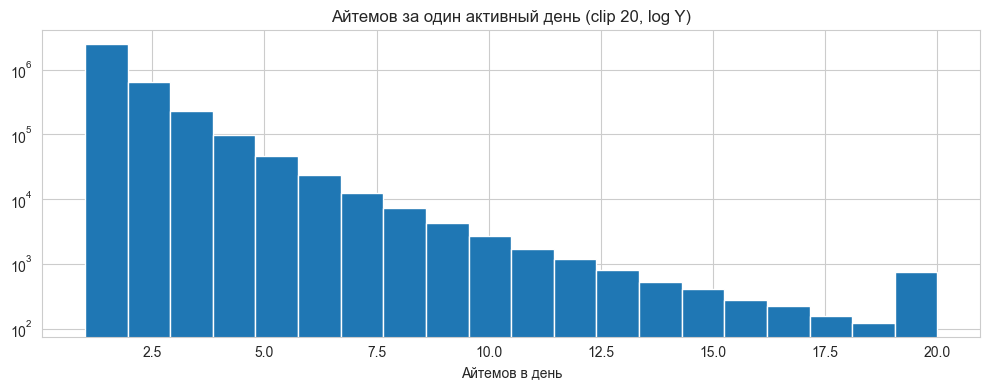

In [ ]:
daily_counts = interactions.groupby(['user_id', interactions['last_watch_dt'].dt.date]).size()

print("Айтемов на активный день:")
print(daily_counts.describe(percentiles=[.25, .5, .75, .9, .99]))

fig, ax = plt.subplots(figsize=(10, 4))
daily_counts.clip(upper=20).hist(bins=20, ax=ax, log=True)
ax.set_title('Айтемов за один активный день (clip 20, log Y)')
ax.set_xlabel('Айтемов в день')
plt.tight_layout()
plt.show()

### Кол-во юзеров с валидным первым днём в val/test (есть взаимодействие в ближайшее время после последней метки с последнего сплита)

In [ ]:
import pandas as pd
from pathlib import Path

PROC = Path('../data/processed')
train = pd.read_parquet(PROC / 'train.parquet')
val   = pd.read_parquet(PROC / 'val.parquet')
test  = pd.read_parquet(PROC / 'test.parquet')

# Для val: контекст = train, таргет = первый активный день в val
train_users = set(train['user_id'].unique())
val_with_ctx = val[val['user_id'].isin(train_users)]

val_first_day = (val_with_ctx
                 .groupby('user_id')['last_watch_dt']
                 .min()
                 .rename('first_day'))
val_joined = val_with_ctx.merge(val_first_day, on='user_id')
val_targets = val_joined[val_joined['last_watch_dt'] == val_joined['first_day']]

print(f"Val: юзеров до фильтра:         {val['user_id'].nunique():,}")
print(f"Val: юзеров с контекстом:       {val_with_ctx['user_id'].nunique():,}")
print(f"Val: юзеров с валидным таргетом: {val_targets['user_id'].nunique():,}")
print(f"Val: таргетов (пар юзер-айтем):  {len(val_targets):,}")
print(f"Val: в среднем айтемов на юзера: {len(val_targets) / val_targets['user_id'].nunique():.2f}")

# Для test: контекст = train + val, таргет = первый активный день в test
context_users = set(train['user_id'].unique()) | set(val['user_id'].unique())
test_with_ctx = test[test['user_id'].isin(context_users)]

test_first_day = (test_with_ctx
                  .groupby('user_id')['last_watch_dt']
                  .min()
                  .rename('first_day'))
test_joined = test_with_ctx.merge(test_first_day, on='user_id')
test_targets = test_joined[test_joined['last_watch_dt'] == test_joined['first_day']]

print(f"\nTest: юзеров до фильтра:         {test['user_id'].nunique():,}")
print(f"Test: юзеров с контекстом:       {test_with_ctx['user_id'].nunique():,}")
print(f"Test: юзеров с валидным таргетом: {test_targets['user_id'].nunique():,}")
print(f"Test: таргетов (пар юзер-айтем):  {len(test_targets):,}")
print(f"Test: в среднем айтемов на юзера: {len(test_targets) / test_targets['user_id'].nunique():.2f}")

Val: юзеров до фильтра:         118,727
Val: юзеров с контекстом:       118,727
Val: юзеров с валидным таргетом: 118,727
Val: таргетов (пар юзер-айтем):  176,224
Val: в среднем айтемов на юзера: 1.48

Test: юзеров до фильтра:         132,323
Test: юзеров с контекстом:       132,323
Test: юзеров с валидным таргетом: 132,323
Test: таргетов (пар юзер-айтем):  186,690
Test: в среднем айтемов на юзера: 1.41


*Данные уже были отфильтрованы через data.py, поэтому конкретно здесь кол-во до фильрации и после совпадают*

### Оценка кол-ва повторных таргетов, что уже были в выборке

In [ ]:
context_pairs = pd.concat([
    train[['user_id', 'item_id']],
    val[['user_id', 'item_id']]
]).drop_duplicates()

context_set = set(map(tuple, context_pairs.values))
test_pairs = set(map(tuple, test_targets[['user_id', 'item_id']].values))

intersection = test_pairs & context_set
print(f"Test таргетов:                {len(test_pairs):,}")
print(f"Из них уже смотрели раньше:   {len(intersection):,} ({len(intersection)/len(test_pairs)*100:.2f}%)")
print(f"Новых (не смотрели):          {len(test_pairs) - len(intersection):,}")

Test таргетов:                186,690
Из них уже смотрели раньше:   0 (0.00%)
Новых (не смотрели):          186,690


*Следствие вывода из блока **Repeat rate** выше: повторных таргетов в парах (user_id, item_id) нет*

## Польза полученных данных для проекта в целом
- **защита от рекомендаций модели только по уже просмотренному**: это не будет приноить профита совсем: *пользователь всё равно не посмотрит это по новой*
- Будущая **Reward-based RL не будет поощрять повторы** (при условии, что reard model научится это понимать)
- Все полученные ранее метрики **честные**, так как test содержит только новые пары

## Ещё одно важное наблюдение
### Вопрос: если повторных пар нет, то как метрики baseline-а last item, который рекомендует просто последний просмотренный, не имеет чисто нулевые метрики?
Это происходит по причине этой части кода:

```bash
def predict(user_id):
    seen = last_item.get(user_id)
    if seen is None:
        return popular   #  <- Опа
    rest = [x for x in popular if x != seen]
    return [seen] + rest    #  <- Опа
```

По сути, в абсолютном большинстве случаев **last-item baseline (или, честнее будет сказать, last-item baseline + popularity fallback) возвращает popularity baseline с переставленным первым элементом**, в следствии чего и получается, что у этих двух подходов почти одинаковые значения по всем метрикам